In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('../data/processed/features.csv')
df = df.sort_values(['Date', 'Store'])

# Calculate Log Sales
Y_raw = df.pivot(index='Date', columns='Store', values='Weekly_Sales').values 
Y_log = np.log1p(Y_raw)

# We want to predict: Change = Log(t) - Log(t-1)
Y_diff = np.diff(Y_log, axis=0) # This makes the data Stationary

# The "Base" is the value at (t-1) which we add the change to
Y_base = Y_log[:-1] # Corresponds to the "previous" step for every diff

# Align X with Y_diff (drop first row of X because diff lost one row)
feature_cols = [c for c in df.columns if c not in ['Date', 'Store', 'Weekly_Sales', 'sales_log1p']]
scaler_x = StandardScaler()
# Reshape X to (Time, Nodes, Feats)
num_dates = df['Date'].nunique()
num_stores = df['Store'].nunique()
X_all_raw = df[feature_cols].values.reshape(num_dates, num_stores, len(feature_cols))
X_all = scaler_x.fit_transform(X_all_raw.reshape(-1, len(feature_cols))).reshape(num_dates, num_stores, -1)

# Drop first row of X to match Y_diff length
X_all = X_all[1:] 

In [3]:
import torch
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

# 1. Define Split (Train on first ~80%, Test on last ~20%)
TRAIN_SPLIT = int(len(Y_diff) * 0.8)
WINDOW_SIZE = 12

# Inputs
X_train = X_all[:TRAIN_SPLIT]
X_test = X_all[TRAIN_SPLIT:]

# Targets (The DIFFERENCE, not the Log)
Y_train_diff = Y_diff[:TRAIN_SPLIT]
Y_test_diff = Y_diff[TRAIN_SPLIT:]

# Bases (The Log Value at t-1) - Do NOT scale this, we just add it back later
Base_train = Y_base[:TRAIN_SPLIT]
Base_test = Y_base[TRAIN_SPLIT:]

# Scale the Targets (Differences are small, roughly -0.5 to 0.5)
scaler_y = StandardScaler()
Y_train_scaled = scaler_y.fit_transform(Y_train_diff)
Y_test_scaled = scaler_y.transform(Y_test_diff)

# Dataset Creator
def create_dataset(x, y, base, window):
    X_seq, Y_seq, Base_seq = [], [], []
    # We need to predict t+1 given t..t-window
    # But 'y' is already aligned such that y[i] is the target for x[i]
    # Wait! Standard windowing: Input [t-w : t], Target [t]
    for i in range(len(x) - window):
        X_seq.append(x[i : i + window])
        Y_seq.append(y[i + window])      # Predict Diff at this step
        Base_seq.append(base[i + window]) # Keep Base at this step for reconstruction
    return np.array(X_seq), np.array(Y_seq), np.array(Base_seq)

X_train_win, Y_train_win, _ = create_dataset(X_train, Y_train_scaled, Base_train, WINDOW_SIZE)
X_test_win, Y_test_win, Base_test_win = create_dataset(X_test, Y_test_scaled, Base_test, WINDOW_SIZE)
# 4. PyTorch Loaders
# The model expects (Batch, Features, Nodes, Time)
# But we have (Batch, Time, Nodes, Features) -> We must permute
tensor_x_train = torch.FloatTensor(X_train_win).permute(0, 3, 2, 1) 
tensor_y_train = torch.FloatTensor(Y_train_win)

tensor_x_test = torch.FloatTensor(X_test_win).permute(0, 3, 2, 1)
tensor_y_test = torch.FloatTensor(Y_test_win)

train_loader = DataLoader(TensorDataset(
    torch.FloatTensor(X_train_win).permute(0, 3, 2, 1), 
    torch.FloatTensor(Y_train_win)
), batch_size=32, shuffle=True)

test_loader = DataLoader(TensorDataset(
    torch.FloatTensor(X_test_win).permute(0, 3, 2, 1), 
    torch.FloatTensor(Y_test_win),
    torch.FloatTensor(Base_test_win)
), batch_size=32, shuffle=False)

print(f"Input Batch Shape: {tensor_x_train.shape}") 
# Expected: (Samples, 34, 45, 12) -> (Batch, Feats, Nodes, Time)

Input Batch Shape: torch.Size([101, 34, 45, 12])


In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class GraphLearner(nn.Module):
    def __init__(self, num_nodes, dim):
        super().__init__()
        # Learnable embeddings for the 45 stores
        self.emb1 = nn.Embedding(num_nodes, dim)
        self.emb2 = nn.Embedding(num_nodes, dim)
        self.lin1 = nn.Linear(dim, dim)
        self.lin2 = nn.Linear(dim, dim)

    def forward(self):
        # Calculate similarity between stores
        nodevec1 = self.lin1(self.emb1.weight)
        nodevec2 = self.lin2(self.emb2.weight)
        # A = ReLU(E1 * E2^T) -> Adjacency Matrix
        adj = F.softmax(F.relu(torch.mm(nodevec1, nodevec2.transpose(0, 1))), dim=1)
        return adj

In [5]:
class TemporalGNN(nn.Module):
    def __init__(self, num_nodes, in_channels, out_channels, window_size):
        super().__init__()
        self.num_nodes = num_nodes
        
        # 1. Graph Learner: Learns relations between the 45 stores
        self.graph_learner = GraphLearner(num_nodes, dim=40)
        
        # 2. Input Projection
        self.start_conv = nn.Conv2d(in_channels, 32, kernel_size=(1,1))
        
        # 3. Temporal Block (Dilated Convolutions)
        # Captures trends like "lag_52" efficiently
        self.tcn = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=(1, 3), dilation=1, padding=(0,1)),
            nn.GELU(),
            nn.Conv2d(64, 32, kernel_size=(1, 3), dilation=2, padding=(0,2))
        )
        
        # 4. Graph Convolution (Spatial Block)
        # Aggregates info from correlated stores
        self.gcn_weight = nn.Parameter(torch.randn(32, 32))
        
        # 5. Output Projection
        self.end_conv = nn.Conv2d(32, out_channels, kernel_size=(1,1))
        
    def forward(self, x):
        # x shape: (Batch, Features, Nodes, Time)
        
        # 1. Learn the Graph
        adj = self.graph_learner() # [45, 45]
        
        # 2. Initial Feature Extraction
        x = self.start_conv(x)
        skip = x
        
        # 3. Temporal Processing
        x = self.tcn(x)
        
        # 4. Spatial Processing (Manual GCN implementation for simplicity)
        # AXW operation: Propagate info across the learned graph
        # (Batch, Channels, Nodes, Time) -> Permute for matmul
        B, C, N, T = x.shape
        x_reshape = x.permute(0, 3, 2, 1).reshape(B*T, N, C) 
        # Graph Conv: Adj * X * Weight
        out = torch.matmul(adj, x_reshape) 
        out = torch.matmul(out, self.gcn_weight)
        
        x = out.reshape(B, T, N, C).permute(0, 3, 2, 1) + skip # Residual connection
        
        # 5. Final Prediction
        # We usually take the last time step to predict the future
        x = x[:, :, :, -1:] 
        x = self.end_conv(x)
        return x # Shape: (Batch, 1, 45, 1) -> Prediction for each store

In [92]:
# Hyperparameters
num_nodes = 45
in_channels = X_all.shape[2] # ~34 features
out_channels = 1 # Predicting 1 value (Sales)
window_size = WINDOW_SIZE

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = TemporalGNN(num_nodes, in_channels, out_channels, window_size).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="min", patience=5,factor=0.5)
criterion = torch.nn.SmoothL1Loss() # MAE is better for Sales than MSE

In [93]:
import os

epochs = 150
train_losses = []
test_losses = []

for epoch in range(epochs):
    # --- Training ---
    model.train()
    batch_loss = []
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        
        optimizer.zero_grad()
        
        # Forward pass
        # Output shape: (Batch, 1, Nodes, 1) -> Squeeze to (Batch, Nodes)
        pred = model(bx).squeeze(-1).squeeze(1)
        
        loss = criterion(pred, by)
        loss.backward()
        optimizer.step()
        
        batch_loss.append(loss.item())
    
    train_avg = np.mean(batch_loss)
    train_losses.append(train_avg)

    # --- Validation ---
    model.eval()
    val_batch_loss = []
    with torch.no_grad():
        for bx, by,_ in test_loader:
            bx, by = bx.to(device), by.to(device)
            pred = model(bx).squeeze(-1).squeeze(1)
            loss = criterion(pred, by)
            val_batch_loss.append(loss.item())
    
    val_loss = np.mean(val_batch_loss)
    scheduler.step(val_loss)
    test_avg = np.mean(val_batch_loss)
    test_losses.append(test_avg)
    
    if epoch % 10 == 0:
        print(f"Epoch {epoch}: Train MAE={train_avg:.4f}, Test MAE={test_avg:.4f}")

# Save model + training artifacts
os.makedirs('../checkpoints', exist_ok=True)
checkpoint = {
    'epoch': epochs,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'train_losses': train_losses,
    'test_losses': test_losses,
    'scaler_x': scaler_x,
    'scaler_y': scaler_y,
}
torch.save(checkpoint, '../checkpoints/temporal_gnn_checkpoint.pt')
# Save full model object for easy reload (optional)
torch.save(model, '../checkpoints/temporal_gnn_full_model.pth')

print("Saved checkpoint to '../checkpoints/temporal_gnn_checkpoint.pt' and full model to '../checkpoints/temporal_gnn_full_model.pth'")

Epoch 0: Train MAE=0.4290, Test MAE=0.1611
Epoch 10: Train MAE=0.2696, Test MAE=0.1409
Epoch 20: Train MAE=0.3418, Test MAE=0.1252
Epoch 30: Train MAE=0.2022, Test MAE=0.1327
Epoch 40: Train MAE=0.1847, Test MAE=0.1292
Epoch 50: Train MAE=0.2731, Test MAE=0.1301
Epoch 60: Train MAE=0.2018, Test MAE=0.1297
Epoch 70: Train MAE=0.1929, Test MAE=0.1297
Epoch 80: Train MAE=0.2665, Test MAE=0.1297
Epoch 90: Train MAE=0.2777, Test MAE=0.1297
Epoch 100: Train MAE=0.2641, Test MAE=0.1297
Epoch 110: Train MAE=0.2014, Test MAE=0.1297
Epoch 120: Train MAE=0.2525, Test MAE=0.1297
Epoch 130: Train MAE=0.2917, Test MAE=0.1297
Epoch 140: Train MAE=0.1910, Test MAE=0.1297
Saved checkpoint to 'checkpoints/temporal_gnn_checkpoint.pt' and full model to 'checkpoints/temporal_gnn_full_model.pth'


In [8]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

full_model_path = '../checkpoints/temporal_gnn_full_model.pth'
model = torch.load(full_model_path, map_location=device)  # returns model object
model.eval()

with torch.no_grad():
    adj_matrix_full = model.graph_learner().detach().cpu().numpy()
print("Loaded full model; adj shape:", adj_matrix_full.shape)

model.eval()
preds_diff_scaled = []
actuals_diff_scaled = []
bases = []

with torch.no_grad():
    for bx, by, base in test_loader:
        bx = bx.to(device)
        preds_diff_scaled.append(model(bx).squeeze().cpu().numpy())
        actuals_diff_scaled.append(by.numpy())
        bases.append(base.numpy())

# Concat
preds_diff_scaled = np.concatenate(preds_diff_scaled)
bases = np.concatenate(bases)
actuals_diff_scaled = np.concatenate(actuals_diff_scaled)

# A. Inverse Scale the "Difference"
preds_diff = scaler_y.inverse_transform(preds_diff_scaled)
actuals_diff = scaler_y.inverse_transform(actuals_diff_scaled)

# B. Reconstruct Log Sales: Log(t) = Log(t-1) + Diff(t)
preds_log = bases + preds_diff
actuals_log = bases + actuals_diff

# C. Inverse Log (Back to Real Dollars)
preds_dollar = np.expm1(preds_log)
actuals_dollar = np.expm1(actuals_log)

# Metrics
mape = np.mean(np.abs((actuals_dollar - preds_dollar) / actuals_dollar)) * 100
print(f"\nFINAL STATIONARY MAPE: {mape:.2f}%")

C:\Users\HP\AppData\Local\Temp\ipykernel_23332\3282506220.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model = torch.load(full_model_path, map_location=device)  # ret

Loaded full model; adj shape: (45, 45)

FINAL STATIONARY MAPE: 4.94%


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Use default matplotlib style
plt.style.use('default')

# ==========================================
# Plot 1: Training vs Validation Loss
# Checks for overfitting and convergence
# ==========================================
plt.figure(figsize=(12, 5))
plt.plot(train_losses, label='Training Loss (MAE)', linewidth=2, color='blue')
plt.plot(test_losses, label='Validation Loss (MAE)', linewidth=2, color='orange')
plt.title('Model Convergence: Training vs Validation Loss', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Loss (MAE)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ==========================================
# Plot 2: Actual vs Predicted Sales (Specific Store)
# Visually inspect how well the model tracks trends
# ==========================================
store_idx = 0  # Change this (0-44) to see different stores
subset_len = 50 # View last 50 weeks for clarity

plt.figure(figsize=(15, 6))
plt.plot(actuals_dollar[-subset_len:, store_idx], label='Actual Sales', marker='o', markersize=4, linewidth=2, color='tab:blue')
plt.plot(preds_dollar[-subset_len:, store_idx], label='GNN Prediction', linestyle='--', linewidth=2, color='tab:red')
plt.title(f'Forecast vs Actuals: Store {store_idx+1}', fontsize=16)
plt.xlabel('Time (Weeks in Test Set)')
plt.ylabel('Weekly Sales ($)')
plt.legend(fontsize=12)
plt.show()


In [31]:
model.eval()
# Extract the learned matrix from the GraphLearner module
adj_matrix = model.graph_learner().detach().cpu().numpy()
print("Learned Adjacency Matrix shape:", adj_matrix.shape)

Learned Adjacency Matrix shape: (45, 45)


C:\Users\HP\AppData\Local\Temp\ipykernel_23332\1857337729.py:64: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



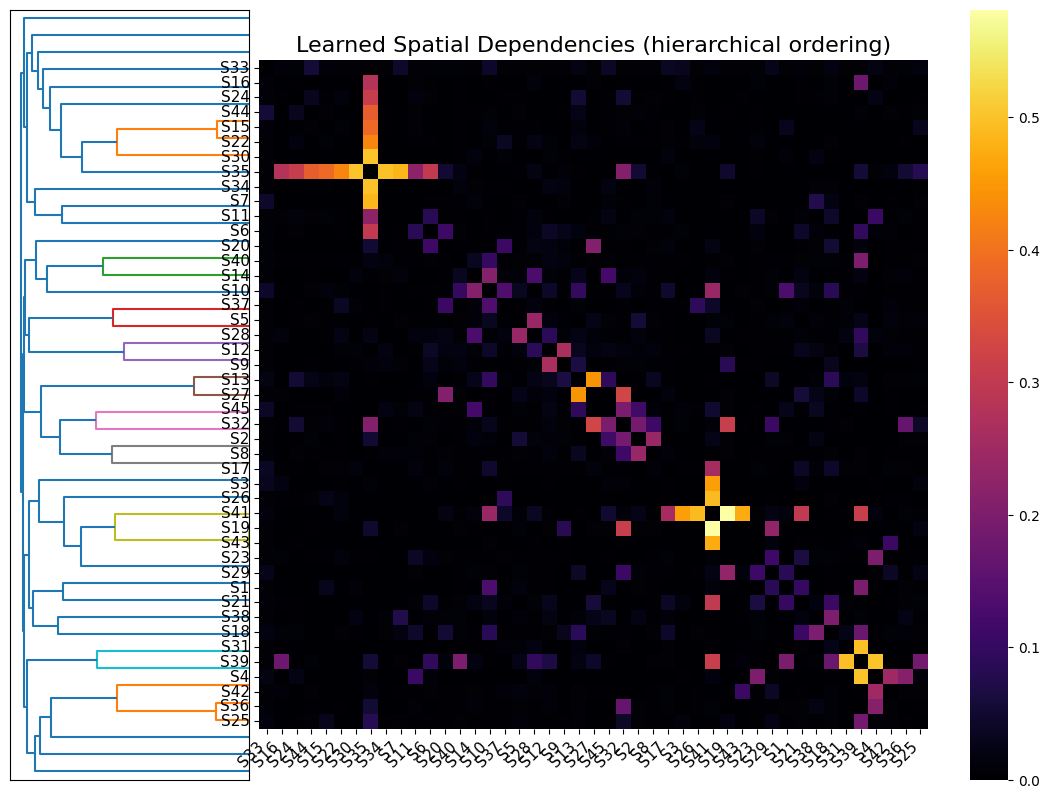

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.cluster.hierarchy as sch
from scipy.spatial.distance import squareform

# symmetric affinity (use symmetric version for clustering)
A = np.array(adj_matrix, dtype=float)
A_sym = (A + A.T) / 2.0
np.fill_diagonal(A_sym, 0.0)

# normalize to [0,1] then convert similarity -> distance
amin, amax = A_sym.min(), A_sym.max()
if amax - amin > 0:
    A_norm = (A_sym - amin) / (amax - amin)
else:
    A_norm = A_sym.copy()
dist_mat = 1.0 - A_norm  # higher affinity -> smaller distance

# condensed distance for linkage
condensed = squareform(dist_mat, checks=False)

# linkage + optional optimal leaf ordering for clearer heatmap
Z = sch.linkage(condensed, method='average')
try:
    Z = sch.optimal_leaf_ordering(Z, condensed)
except Exception:
    # optimal_leaf_ordering may not be available in older SciPy; fallback to Z
    pass

# get leaf order and reorder matrix + labels
leaves = sch.leaves_list(Z)
labels = [f"S{i+1}" for i in range(A.shape[0])]
labels_ord = [labels[i] for i in leaves]
A_reordered = A_sym[np.ix_(leaves, leaves)]

# store for later use
adj_matrix_reordered = A_reordered
labels_reordered = labels_ord

# Plot dendrogram + heatmap side-by-side
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 3.5], wspace=0.02)

# dendrogram (rows)
ax0 = fig.add_subplot(gs[0])
sch.dendrogram(Z, orientation='left', labels=labels_ord, leaf_font_size=10, ax=ax0)
ax0.set_yticks([])
ax0.set_xticks([])
ax0.invert_yaxis()

# heatmap
ax1 = fig.add_subplot(gs[1])
sns.heatmap(A_reordered,
            cmap='inferno',
            square=True,
            vmin=0, vmax=A_reordered.max(),
            xticklabels=labels_ord,
            yticklabels=labels_ord,
            ax=ax1)
ax1.set_xticklabels(labels_ord, rotation=45, ha='right', fontsize=11)
ax1.set_yticklabels(labels_ord, rotation=0, fontsize=11)
ax1.set_title('Learned Spatial Dependencies (hierarchical ordering)', fontsize=16)
plt.tight_layout()
plt.show()

In [38]:
import numpy as np
import pandas as pd
import networkx as nx

# use symmetric affinity (if you reordered earlier you can swap in adj_matrix_reordered)
A = np.array(adj_matrix, dtype=float)
A_sym = (A + A.T) / 2.0
np.fill_diagonal(A_sym, 0.0)
N = A_sym.shape[0]

# labels
try:
    labels_use = labels_reordered
except NameError:
    labels_use = [f"S{i+1}" for i in range(N)]

# Basic measures
strength = A_sym.sum(axis=1)                      # weighted degree (sum of affinities)
degree_count = (A_sym > 0).sum(axis=1)            # number of non-zero neighbors

# Build graphs for centralities
G_aff = nx.from_numpy_array(A_sym)                 # affinity graph (weights = 'weight')

# For path-based centralities we need distance weights: convert affinity -> distance
eps = 1e-12
dist_mat = np.where(A_sym > 0, 1.0 / (A_sym + eps), 1e6)  # large cost for absent edges
G_dist = nx.from_numpy_array(dist_mat)

# Compute centralities (weighted where appropriate)
eig = nx.eigenvector_centrality_numpy(G_aff, weight='weight')
pagerank = nx.pagerank(G_aff, weight='weight')
betw = nx.betweenness_centrality(G_dist, weight='weight', normalized=True)
closeness = nx.closeness_centrality(G_dist, distance='weight')
clustering = nx.clustering(G_aff, weight='weight')  # weighted clustering coeff

# Aggregate into DataFrame
df_cent = pd.DataFrame({
    'Store': labels_use,
    'Strength': strength,
    'Degree': degree_count,
    'Eigenvector': [eig[i] for i in range(N)],
    'PageRank': [pagerank[i] for i in range(N)],
    'Betweenness': [betw[i] for i in range(N)],
    'Closeness': [closeness[i] for i in range(N)],
    'Clustering': [clustering[i] for i in range(N)]
})

# Rank each metric (rank 1 = best/highest)
rank_cols = ['Strength','Eigenvector','PageRank','Closeness','Clustering']
for c in rank_cols:
    df_cent[f'Rank_{c}'] = df_cent[c].rank(method='average', ascending=False)

# For betweenness smaller is worse; higher is better so rank descending as well
df_cent['Rank_Betweenness'] = df_cent['Betweenness'].rank(method='average', ascending=False)
df_cent['Rank_Degree'] = df_cent['Degree'].rank(method='average', ascending=False)

# Mean rank summary
rank_cols_all = [col for col in df_cent.columns if col.startswith('Rank_')]
df_cent['Mean_Rank'] = df_cent[rank_cols_all].mean(axis=1)
df_cent = df_cent.sort_values('Mean_Rank').reset_index(drop=True)

# Save and print top/bottom
df_cent.to_csv('../results/graph/store_centrality_metrics.csv', index=False)
print("Saved centrality metrics to store_centrality_metrics.csv\n")
print("Top 5 stores by mean centrality rank:")
print(df_cent[['Store','Mean_Rank']].head(5).to_string(index=False))
print("\nBottom 5 stores by mean centrality rank:")
print(df_cent[['Store','Mean_Rank']].tail(5).to_string(index=False))

Saved centrality metrics to store_centrality_metrics.csv

Top 5 stores by mean centrality rank:
Store  Mean_Rank
  S39   5.000000
  S29   5.000000
  S18   5.428571
  S19   6.857143
  S28  10.285714

Bottom 5 stores by mean centrality rank:
Store  Mean_Rank
  S38  33.642857
  S27  33.928571
   S4  33.928571
  S21  34.000000
  S35  35.214286


In [25]:
import numpy as np

A = adj_matrix.copy()
N = A.shape[0]
print("shape:", A.shape)
print("min, max, mean, median, std:", A.min(), A.max(), A.mean(), np.median(A), A.std())
print("abs-min, abs-max:", np.abs(A).min(), np.abs(A).max())
print("percentiles:", {p: np.percentile(A, p) for p in [50,75,90,95,99]})

# If symmetric:
print("is_symmetric:", np.allclose(A, A.T, atol=1e-6))

# Check row sums (to detect row normalization):
row_sums = A.sum(axis=1)
print("row sums: min, max, mean:", row_sums.min(), row_sums.max(), row_sums.mean())
# If using non-negative adj (e.g., after softmax) also check:
if (A >= -1e-9).all():
    print("non-negative entries (possible softmax/sigmoid based).")

# Top-k edges (absolute):
k = 20
flat_inds = np.dstack(np.unravel_index(np.argsort(np.abs(A.ravel()))[::-1], A.shape))[0]
top_k = [(int(i), int(j), A[i,j]) for (i,j) in flat_inds[:k]]
print("Top-k strongest (abs) edges:", top_k)


shape: (45, 45)
min, max, mean, median, std: 4.471101e-07 0.999806 0.022222223 0.0020355368 0.09553231
abs-min, abs-max: 4.471101e-07 0.999806
percentiles: {50: np.float32(0.0020355368), 75: np.float32(0.0054793493), 90: np.float32(0.021852937), 95: np.float32(0.07611182), 99: np.float32(0.54429823)}
is_symmetric: False
row sums: min, max, mean: 0.9999999 1.0000002 1.0
non-negative entries (possible softmax/sigmoid based).
Top-k strongest (abs) edges: [(29, 34, np.float32(0.999806)), (3, 38, np.float32(0.9971021)), (33, 34, np.float32(0.9940095)), (25, 40, np.float32(0.9744702)), (30, 38, np.float32(0.9695124)), (6, 34, np.float32(0.96795243)), (18, 40, np.float32(0.96650845)), (42, 40, np.float32(0.9460601)), (2, 40, np.float32(0.9118185)), (21, 34, np.float32(0.8494413)), (14, 34, np.float32(0.7657218)), (43, 34, np.float32(0.7401035)), (26, 31, np.float32(0.6447324)), (31, 18, np.float32(0.6195065)), (38, 40, np.float32(0.6180883)), (23, 34, np.float32(0.61573404)), (12, 26, np.floa

In [33]:
A[36]

array([0.00351519, 0.00199524, 0.00199524, 0.00199524, 0.00207641,
       0.00639064, 0.00199524, 0.00199524, 0.00199524, 0.26391098,
       0.00199817, 0.00306351, 0.01662151, 0.01974089, 0.00376272,
       0.00199524, 0.00199524, 0.00199524, 0.00199524, 0.21309327,
       0.01769333, 0.07191314, 0.00199524, 0.00581092, 0.00199524,
       0.17906487, 0.00199524, 0.01245649, 0.00199524, 0.0164595 ,
       0.02145256, 0.00199524, 0.00199524, 0.00468533, 0.00199524,
       0.00199524, 0.00359384, 0.00199524, 0.00199524, 0.00199524,
       0.08012536, 0.00461653, 0.00199524, 0.00206432, 0.00199524],
      dtype=float32)

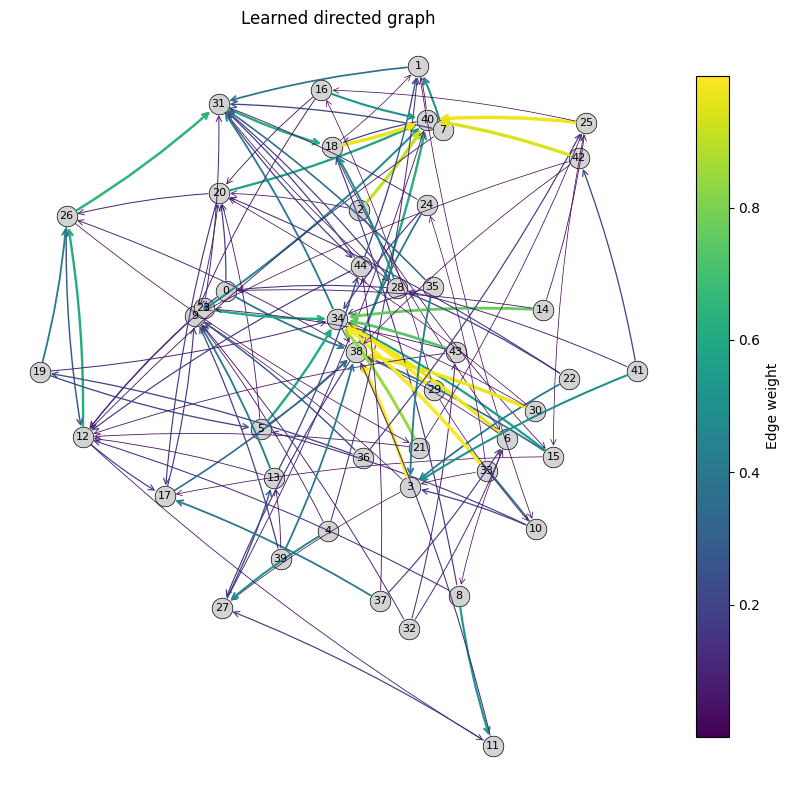

In [28]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

def save_directed_graph(adj, out_path="../results/figures/directed_graph.pdf", top_k=3, figsize=(6,6), seed=42):
    """
    Save a directed graph visualization (PDF/SVG) from a row-normalized adjacency matrix.
    Keeps top_k outgoing neighbors per node to reduce clutter.
    """
    A = np.array(adj, dtype=float)
    N = A.shape[0]

    # Build directed graph keeping top_k outgoing edges per node
    G = nx.DiGraph()
    for i in range(N):
        # get indices of top_k largest entries in row i
        if top_k >= N:
            idx = np.arange(N)
        else:
            idx = np.argpartition(-A[i], top_k)[:top_k]
        for j in idx:
            w = float(A[i, j])
            if w > 1e-12:
                G.add_edge(i, j, weight=w)

    # layout
    pos = nx.spring_layout(G, seed=seed)

    # prepare figure + axis
    fig, ax = plt.subplots(figsize=figsize)

    # nodes
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=220, node_color='lightgray', edgecolors='k', linewidths=0.5)

    # edges: draw each edge individually so we can set a color / width per edge
    edge_weights = np.array([d['weight'] for (_,_,d) in G.edges(data=True)])
    if edge_weights.size == 0:
        print("No edges to draw (all zero or top_k too small).")
        return

    # normalize weights for linewidths
    wmin, wmax = edge_weights.min(), edge_weights.max()
    widths = 0.5 + 2.0 * (edge_weights - wmin) / (wmax - wmin + 1e-12)

    # We'll use a ScalarMappable for the colorbar (viridis colormap)
    cmap = plt.cm.viridis
    norm = plt.Normalize(vmin=edge_weights.min(), vmax=edge_weights.max())
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array(edge_weights)  # attach data to sm

    # Draw edges with colored lines (map weight -> color)
    edges = list(G.edges(data=True))
    for (u, v, d), lw in zip(edges, widths):
        w = d['weight']
        color = cmap(norm(w))
        # Use connectionstyle small curvature for better visibility of direction
        ax.annotate("",
                    xy=pos[v], xycoords='data',
                    xytext=pos[u], textcoords='data',
                    arrowprops=dict(arrowstyle="->", color=color, lw=lw, shrinkA=8, shrinkB=8,
                                    connectionstyle="arc3,rad=0.05"),
                    )

    # labels
    labels = {n: str(n) for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels, font_size=8, ax=ax)

    # colorbar attached to the figure and the axis
    cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Edge weight")

    ax.set_title("Learned directed graph")
    ax.set_axis_off()
    plt.tight_layout()
    fig.savefig(out_path, format='pdf', dpi=300)
    plt.show()
    # plt.close(fig)
    
save_directed_graph(adj_matrix_full,
                    out_path="../results/figures/learned_directed_graph.pdf",
                    top_k=3,
                    figsize=(8,8),
                    seed=42)

In [126]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import community

def plot_store_graph_static(adj_matrix,
                            node_labels=None,
                            node_strengths=None,
                            threshold=None,
                            top_k_edges=None,
                            figsize=(12,12),
                            cmap='viridis'):
    """
    Stable visualization for NumPy 2.0+.
    adj_matrix: (N,N) numpy array
    node_labels: optional list of length N (strings)
    node_strengths: optional 1D array length N to scale node sizes (e.g., total sales)
    threshold: keep edges with weight >= threshold (float)
    top_k_edges: alternatively keep only top_k strongest edges (int)
    """
    A = np.array(adj_matrix, dtype=float)
    N = A.shape[0]
    assert A.shape == (N, N)

    # Symmetrize and zero diagonal
    A_sym = (A + A.T) / 2.0
    np.fill_diagonal(A_sym, 0.0)

    # Build candidate edges from upper triangle
    triu_idx = np.triu_indices(N, k=1)
    edge_weights = A_sym[triu_idx]
    edges = list(zip(triu_idx[0], triu_idx[1], edge_weights))

    # Filter edges by threshold or top_k_edges
    if threshold is not None:
        edges = [(i,j,w) for (i,j,w) in edges if w >= threshold]
    elif top_k_edges is not None:
        edges_sorted = sorted(edges, key=lambda x: x[2], reverse=True)
        edges = edges_sorted[:top_k_edges]
    else:
        edges = [(i,j,w) for (i,j,w) in edges if w > 1e-9]

    # Create graph
    G = nx.Graph()
    G.add_nodes_from(range(N))
    for i,j,w in edges:
        if w > 0:
            G.add_edge(i, j, weight=float(w))

    # Node strengths (default = node strength from adjacency)
    if node_strengths is None:
        node_strengths = A_sym.sum(axis=1)
    node_strengths = np.array(node_strengths, dtype=float)

    # scale node sizes (safe normalization using np.ptp)
    node_ptp = np.ptp(node_strengths) if np.ptp(node_strengths) != 0 else 1.0
    node_sizes = 300 + (node_strengths - node_strengths.min()) / (node_ptp) * 1200

    # community detection (may fail on tiny graphs)
    try:
        communities = community.greedy_modularity_communities(G)
        comm_map = {}
        for cid, comm in enumerate(communities):
            for node in comm:
                comm_map[node] = cid
        node_colors = [comm_map.get(n, 0) for n in G.nodes()]
    except Exception:
        node_colors = None

    # layout
    pos = nx.spring_layout(G, seed=42, k=0.5)

    # edges widths scaled by weight (safe normalization)
    weights = np.array([d['weight'] for _,_,d in G.edges(data=True)]) if G.number_of_edges() > 0 else np.array([])
    if weights.size > 0:
        w_ptp = np.ptp(weights) if np.ptp(weights) != 0 else 1.0
        widths = 0.5 + (weights - weights.min()) / w_ptp * 4.5
    else:
        widths = []

    plt.figure(figsize=figsize)
    # draw nodes
    nx.draw_networkx_nodes(G, pos,
                           node_size=node_sizes,
                           node_color=node_colors,
                           cmap=plt.get_cmap(cmap),
                           linewidths=0.5, edgecolors='k')
    # draw edges with widths
    if G.number_of_edges() > 0:
        # networkx wants a single width or list aligned with edges
        nx.draw_networkx_edges(G, pos, width=widths, alpha=0.9)
    # labels
    if node_labels is None:
        labels = {i: str(i+1) for i in G.nodes()}
    else:
        labels = {i: lab for i, lab in enumerate(node_labels)}
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=8)

    plt.title('Store Relationship Graph (learned adjacency)')
    plt.axis('off')
    plt.tight_layout()
    plt.show()


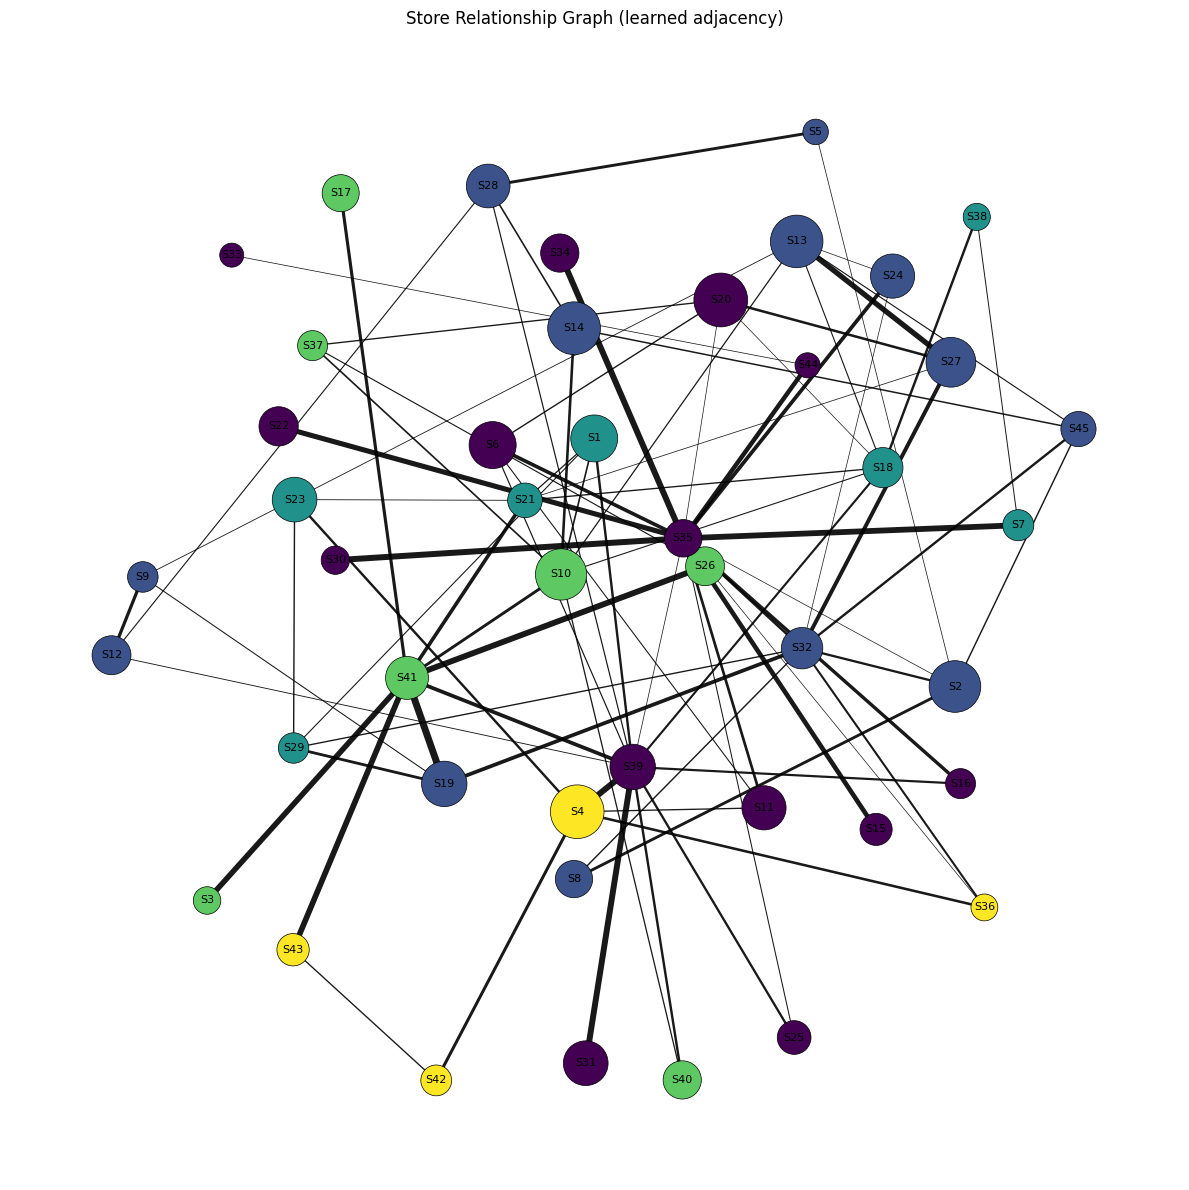

In [127]:
plot_store_graph_static(adj_matrix,
                        threshold=0.05,
                        node_strengths=Y_raw.sum(axis=0),
                        node_labels=[f"S{i+1}" for i in range(adj_matrix.shape[0])])


In [131]:
import numpy as np
import networkx as nx
import plotly.graph_objects as go

def plot_store_graph_interactive(adj_matrix,
                                 node_labels=None,
                                 node_strengths=None,
                                 top_k_edges=120,
                                 width=900, height=900,
                                 title='Interactive Store Relationship Graph',
                                 save_html_path=None):
    """
    Interactive Plotly network for a learned adjacency matrix.

    Parameters
    ----------
    adj_matrix : (N,N) array-like
        Learned affinity / adjacency matrix.
    node_labels : list[str] or None
        Labels for each node. Defaults to "1..N".
    node_strengths : array-like or None
        Numeric values used for node color/size scaling (e.g., total sales).
        If None, uses sum of symmetric adjacency rows.
    top_k_edges : int or None
        Keep only the strongest top_k edges (by weight). If None, uses threshold > 0.
    save_html_path : str or None
        If provided, saves the interactive plot to an HTML file at that path.
    """
    A = np.array(adj_matrix, dtype=float)
    N = A.shape[0]
    assert A.shape == (N, N), "adj_matrix must be square (N,N)"

    # Symmetrize & zero diagonal
    A_sym = (A + A.T) / 2.0
    np.fill_diagonal(A_sym, 0.0)

    # Extract upper-triangle edges
    triu_idx = np.triu_indices(N, k=1)
    weights = A_sym[triu_idx]
    edge_list = list(zip(triu_idx[0], triu_idx[1], weights))

    # Filter by top_k_edges or keep all positive-weight edges
    if top_k_edges is not None:
        edge_list = sorted(edge_list, key=lambda x: x[2], reverse=True)
        edge_list = [e for e in edge_list if e[2] > 0][:top_k_edges]
    else:
        edge_list = [e for e in edge_list if e[2] > 0]

    # Build graph
    G = nx.Graph()
    G.add_nodes_from(range(N))
    for i, j, w in edge_list:
        G.add_edge(int(i), int(j), weight=float(w))

    # Node strengths (for coloring/sizing)
    if node_strengths is None:
        node_strengths = A_sym.sum(axis=1)
    node_strengths = np.asarray(node_strengths, dtype=float)

    # Normalize node sizes: map to reasonable marker sizes
    node_min, node_max = node_strengths.min(), node_strengths.max()
    node_ptp = (node_max - node_min) if (node_max - node_min) != 0 else 1.0
    node_size = 10 + (node_strengths - node_min) / node_ptp * 30  # sizes in [10, 40]

    # Layout (use spring for readability)
    pos = nx.spring_layout(G, seed=42, k=0.8)

    # Build edge traces
    edge_x = []
    edge_y = []
    edge_widths = []
    edge_weights = []
    for u, v, d in G.edges(data=True):
        x0, y0 = pos[u]
        x1, y1 = pos[v]
        edge_x += [x0, x1, None]
        edge_y += [y0, y1, None]
        w = d.get('weight', 1.0)
        edge_weights.append(w)

    # Normalize edge widths for plotting
    if len(edge_weights) > 0:
        ew_min, ew_max = min(edge_weights), max(edge_weights)
        ew_ptp = (ew_max - ew_min) if (ew_max - ew_min) != 0 else 1.0
        edge_widths_norm = [0.5 + (w - ew_min) / ew_ptp * 4.5 for w in edge_weights]
    else:
        edge_widths_norm = []

    # Since Plotly expects a single continuous line trace for edges, build one trace with constant style.
    edge_trace = go.Scatter(
        x=edge_x,
        y=edge_y,
        line=dict(width=1, color='#888'),
        hoverinfo='none',
        mode='lines'
    )

    # Node scatter
    node_x = []
    node_y = []
    node_text = []
    for n in G.nodes():
        x, y = pos[n]
        node_x.append(x)
        node_y.append(y)
        if node_labels is None:
            node_text.append(f"Store {n+1}<br>Strength: {node_strengths[n]:.2f}")
        else:
            node_text.append(f"{node_labels[n]}<br>Strength: {node_strengths[n]:.2f}")

    node_trace = go.Scatter(
        x=node_x,
        y=node_y,
        mode='markers+text',
        text=[(node_labels[n] if node_labels is not None else str(n+1)) for n in range(N)],
        textposition='top center',
        hoverinfo='text',
        marker=dict(
            showscale=True,
            colorscale='Viridis',
            reversescale=False,
            color=node_strengths,
            size=node_size,
            colorbar=dict(title='Node strength'),
            line_width=1
        ),
        hovertext=node_text
    )

    fig = go.Figure(data=[edge_trace, node_trace],
                    layout=go.Layout(
                        title=title,
                        title_x=0.5,
                        showlegend=False,
                        width=width,
                        height=height,
                        margin=dict(b=20,l=5,r=5,t=40),
                        hovermode='closest'
                    ))

    # If you want per-edge hover info: add invisible scatter markers at edge midpoints
    if len(edge_list) > 0:
        ex = []
        ey = []
        etext = []
        for (u, v, w) in edge_list:
            x0, y0 = pos[u]; x1, y1 = pos[v]
            ex.append((x0 + x1) / 2.0)
            ey.append((y0 + y1) / 2.0)
            etext.append(f"{(u+1)} ↔ {(v+1)}<br>Weight: {w:.4f}")

        edge_mid_trace = go.Scatter(
            x=ex, y=ey,
            mode='markers',
            marker=dict(size=[max(3, s) for s in edge_widths_norm], color='rgba(0,0,0,0)'),
            hoverinfo='text',
            hovertext=etext,
            showlegend=False
        )
        fig.add_trace(edge_mid_trace)

    fig.update_layout(xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                      yaxis=dict(showgrid=False, zeroline=False, showticklabels=False))

    # fig.show()

    if save_html_path is not None:
        fig.write_html(save_html_path)
        print(f"Saved interactive graph to {save_html_path}")

plot_store_graph_interactive(adj_matrix, node_labels=[f"S{i+1}" for i in range(adj_matrix.shape[0])],
                             node_strengths=Y_raw.sum(axis=0), top_k_edges=120, save_html_path='../results/graph/store_graph.html')


Saved interactive graph to store_graph.html


In [96]:
import pandas as pd
import numpy as np

# 1. Initialize list to store metrics
metrics_list = []

# 2. Loop through each store (0 to 44)
num_stores = actuals_dollar.shape[1]

for i in range(num_stores):
    act = actuals_dollar[:, i]
    pred = preds_dollar[:, i]
    
    # Calculate Metrics
    mae = np.mean(np.abs(pred - act))
    rmse = np.sqrt(np.mean((pred - act)**2))
    # Add small epsilon (1e-6) to avoid division by zero error
    mape = np.mean(np.abs((act - pred) / (act + 1e-6))) * 100
    
    metrics_list.append({
        'Store': i + 1,
        'MAE ($)': mae,
        'RMSE ($)': rmse,
        'MAPE (%)': mape
    })

# 3. Convert to DataFrame for nice formatting
results_df = pd.DataFrame(metrics_list)

# 4. Sort by Accuracy (Lowest MAPE is best)
results_df = results_df.sort_values('MAPE (%)')

# 5. Print the Table
print("="*60)
print("STORE-WISE PERFORMANCE METRICS (Sorted by Accuracy)")
print("="*60)
# Format floats to 2 decimal places with commas for dollars
print(results_df.to_string(index=False, float_format=lambda x: "{:,.2f}".format(x)))
print("="*60)
results_df.to_csv('../results/metrics/gnn_results.csv', index=False)

# 6. Print Summary Highlights
best_store = results_df.iloc[0]
worst_store = results_df.iloc[-1]

print(f"\nBest Performing:  Store {int(best_store['Store'])} (MAPE: {best_store['MAPE (%)']:.2f}%)")
print(f"Worst Performing: Store {int(worst_store['Store'])} (MAPE: {worst_store['MAPE (%)']:.2f}%)")

STORE-WISE PERFORMANCE METRICS (Sorted by Accuracy)
 Store    MAE ($)   RMSE ($)  MAPE (%)
    37  10,923.20  13,727.14      2.08
    30  10,152.60  13,397.40      2.35
    34  34,038.29  41,415.80      3.53
     8  33,284.89  42,026.07      3.69
     9  20,326.01  25,551.21      3.73
    25  26,037.31  31,854.17      3.75
     5  12,082.79  15,158.76      3.75
    32  44,763.20  57,924.92      3.78
    12  36,653.20  45,437.23      3.85
    10  67,696.53  84,677.12      3.86
    43  24,541.88  31,420.78      3.97
    31  54,028.99  64,127.90      3.98
    15  23,263.51  29,454.20      3.98
    26  43,002.66  51,264.04      4.07
    13  84,400.38 102,938.47      4.15
    44  14,343.26  18,502.12      4.19
     6  65,758.82  90,249.39      4.24
     2  78,685.85  90,223.46      4.25
     4  93,711.26 107,445.15      4.40
     1  72,270.77  93,114.60      4.61
    22  46,240.93  56,373.53      4.62
     3  19,127.42  23,033.30      4.69
    40  47,840.04  70,638.95      4.71
    19  67,5

In [ ]:

# --- Existing NTAE calculations (keeps prior logic) ---
abs_err = np.abs(preds_dollar - actuals_dollar)   # shape: (samples, stores)
total_abs_err = abs_err.sum()
total_actual = actuals_dollar.sum()

overall_ntae = total_abs_err / (total_actual + 1e-6) * 100

# Also compute per-store NTAE for diagnostics
per_store_abs = abs_err.sum(axis=0)
per_store_actual = actuals_dollar.sum(axis=0)
per_store_ntae = per_store_abs / (per_store_actual + 1e-6) * 100
mean_per_store_ntae = per_store_ntae.mean()

# 1) Win-Score Rate (WSR) vs persistence baseline (predict last observed = base)
# baseline: predict using previous log (bases) -> convert to dollars
baseline_preds = np.expm1(bases)  # shape: (samples, stores)

# Compare absolute errors: model vs baseline
abs_err_model = abs_err
abs_err_baseline = np.abs(baseline_preds - actuals_dollar)

# Overall win rate: fraction of (week,store) where model error < baseline error
wins = (abs_err_model < abs_err_baseline)
win_rate_overall = wins.sum() / wins.size * 100

# Per-store win rate (fraction of weeks model beats baseline for that store)
per_store_wsr = wins.sum(axis=0) / wins.shape[0] * 100
mean_per_store_wsr = per_store_wsr.mean()

# 2) Per-store MAPE (recomputed for clarity) and P90 (90th percentile)
per_store_mape = np.mean(np.abs((actuals_dollar - preds_dollar) / (actuals_dollar + 1e-6)), axis=0) * 100
p90_mape = np.percentile(per_store_mape, 90)
variance_mape = np.var(per_store_mape)

# 3) Mean Rank across metrics (MAE, RMSE, MAPE)
mae_per_store = np.mean(np.abs(preds_dollar - actuals_dollar), axis=0)
rmse_per_store = np.sqrt(np.mean((preds_dollar - actuals_dollar)**2, axis=0))

df_metrics = pd.DataFrame({
    'Store': np.arange(1, preds_dollar.shape[1] + 1),
    'MAE': mae_per_store,
    'RMSE': rmse_per_store,
    'MAPE': per_store_mape
})

# Rank stores for each metric (ascending: rank 1 = best)
df_metrics['Rank_MAE'] = df_metrics['MAE'].rank(method='average', ascending=True)
df_metrics['Rank_RMSE'] = df_metrics['RMSE'].rank(method='average', ascending=True)
df_metrics['Rank_MAPE'] = df_metrics['MAPE'].rank(method='average', ascending=True)

# Mean Rank
df_metrics['Mean_Rank'] = df_metrics[['Rank_MAE', 'Rank_RMSE', 'Rank_MAPE']].mean(axis=1)

# Sort by Mean Rank to show top/bottom stores
df_metrics_sorted = df_metrics.sort_values('Mean_Rank').reset_index(drop=True)

mean_of_mean_rank = df_metrics['Mean_Rank'].mean()

# Optional: attach WSR & NTAE back to df_metrics for diagnostics
df_metrics['WSR_%'] = per_store_wsr
df_metrics['NTAE_%'] = per_store_ntae
# Save extended diagnostics (optional)
df_metrics_sorted.to_csv('../results/metrics/store_diagnostics_extended.csv', index=False)

# Summary print for convenience
print("\nSummary:")
print(f"- Overall NTAE: {overall_ntae:.4f}%")
print(f"- Win Rate (overall): {win_rate_overall:.2f}%")
print(f"- P90 MAPE: {p90_mape:.2f}%")
print(f"- Variance of per-store MAPE: {variance_mape:.4f}")



Summary:
- Overall NTAE: 4.9325%
- Win Rate (overall): 49.02%
- P90 MAPE: 6.98%
- Variance of per-store MAPE: 1.7583


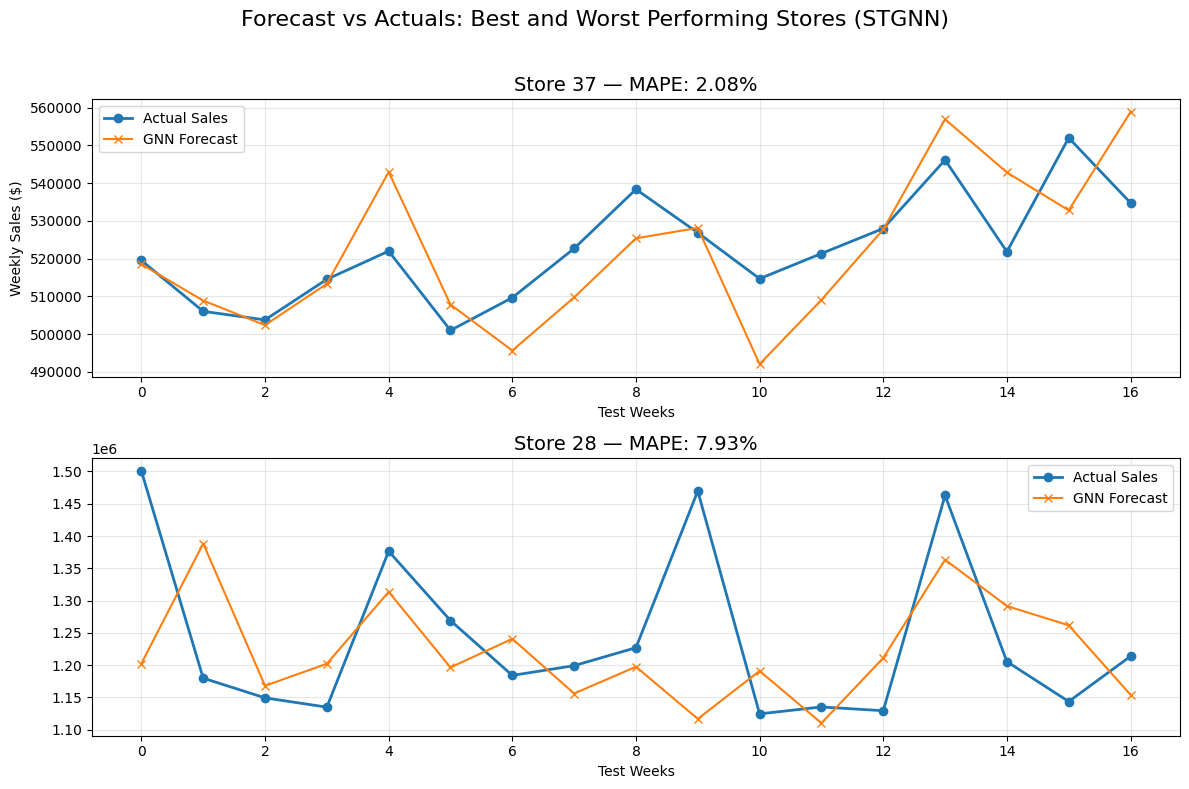

In [119]:
# Combined subplot: Best (store 37) and Worst (store 28) performers
store_ids = [37, 28]  # 1-based IDs from your example
subset_len = min(50, preds_dollar.shape[0])  # plot last up to 50 weeks

# Do NOT share y-axis between subplots
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

for ax, store_id in zip(axes, store_ids):
    idx = store_id - 1
    actual = actuals_dollar[-subset_len:, idx]
    pred = preds_dollar[-subset_len:, idx]
    weeks = np.arange(len(actual))

    # compute store-level MAPE for the plotted window
    mape_store = np.mean(np.abs((actual - pred) / (actual + 1e-6))) * 100

    ax.plot(weeks, actual, label='Actual Sales', linewidth=2, marker='o')
    ax.plot(weeks, pred, label='GNN Forecast',marker='x')
    ax.set_title(f'Store {store_id} — MAPE: {mape_store:.2f}%', fontsize=14)
    ax.set_xlabel('Test Weeks')
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_ylabel('Weekly Sales ($)')
plt.suptitle('Forecast vs Actuals: Best and Worst Performing Stores (STGNN)', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()